In [1]:
from data import load_data

es= load_data('ES=F')

es.head()

[*********************100%***********************]  1 of 1 completed


,close,high,low,open,volume
Datetime,,,,,
2026-10-14 00:09:00-04:00,7873.00,7873.50,7872.75,7873.25,0
2026-10-14 00:10:00-04:00,7873.00,7873.50,7872.75,7872.75,170
2026-10-14 00:11:00-04:00,7873.00,7873.25,7872.75,7873.00,34
2026-10-14 00:12:00-04:00,7873.25,7873.25,7872.50,7873.00,107
2026-10-14 00:13:00-04:00,7873.00,7873.50,7872.75,7873.25,90


In [2]:
from sessions import prepare_rth
from indicators import Indicator



es_rth = prepare_rth(es.copy())
ind = Indicator(es_rth)
es_rth["vwap"] = ind.calculate_session_vwap()

print(es_rth[["close", "volume", "vwap"]].tail(10))

                             close  volume         vwap
Datetime                                               
2026-10-21 10:17:00-04:00  7755.25    4205  7768.811199
2026-10-21 10:18:00-04:00  7757.25    4059  7768.605439
2026-10-21 10:19:00-04:00  7756.00    3157  7768.453149
2026-10-21 10:20:00-04:00  7755.50    2713  7768.316393
2026-10-21 10:21:00-04:00  7754.75    3450  7768.127647
2026-10-21 10:22:00-04:00  7757.00    3210  7767.985295
2026-10-21 10:23:00-04:00  7759.50    7821  7767.723219
2026-10-21 10:24:00-04:00  7758.50    2379  7767.644307
2026-10-21 10:25:00-04:00  7756.00    3491  7767.504449
2026-10-21 10:26:00-04:00  7758.00       0  7767.504449


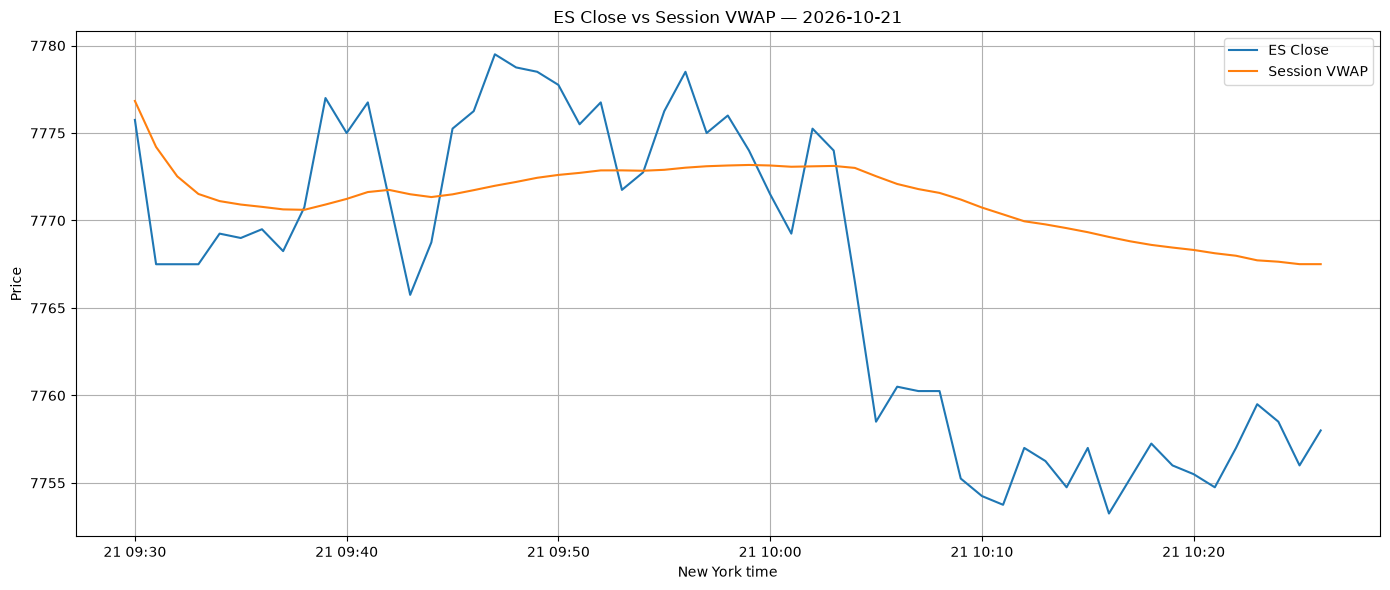

In [3]:
import matplotlib.pyplot as plt

latest_session = es_rth["sessions"].iloc[-1]
day = es_rth[es_rth["sessions"] == latest_session]

plt.figure(figsize=(14, 6))
plt.plot(day.index, day["close"], label="ES Close")
plt.plot(day.index, day["vwap"], label="Session VWAP")

plt.title(f"ES Close vs Session VWAP — {latest_session}")
plt.xlabel("New York time")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [4]:
bands = ind.calculate_vwap_bands()
bands.head()

,vwap,upper_1,lower_1,upper_2,lower_2,upper_3,lower_3
Datetime,,,,,,,
2026-10-14 09:30:00-04:00,7822.583333,7822.583333,7822.583333,7822.583333,7822.583333,7822.583333,7822.583333
2026-10-14 09:31:00-04:00,7823.133000,7823.753443,7822.512557,7824.373886,7821.892113,7824.994330,7821.271670
2026-10-14 09:32:00-04:00,7823.239015,7823.814193,7822.663837,7824.389371,7822.088658,7824.964550,7821.513480
2026-10-14 09:33:00-04:00,7824.007486,7825.764012,7822.250959,7827.520538,7820.494433,7829.277064,7818.737907
2026-10-14 09:34:00-04:00,7824.387228,7826.235910,7822.538546,7828.084592,7820.689864,7829.933274,7818.841182


In [5]:
ind = Indicator(load_data("ES=F"))
signals = ind.get_signal()
print(signals["long"].sum(), signals["short"].sum())

[*********************100%***********************]  1 of 1 completed

26 25


In [6]:
print(
    "Sessions with long signals:",
    es_rth.loc[signals["long"], "sessions"].nunique()
)

print(
    "Sessions with short signals:",
    es_rth.loc[signals["short"], "sessions"].nunique()
)

Sessions with long signals: 6
Sessions with short signals: 5


In [7]:
new_session = es_rth["sessions"].ne(es_rth["sessions"].shift())

long_starts = signals["long"] & (
    ~signals["long"].shift(1, fill_value=False) | new_session
)
short_starts = signals["short"] & (
    ~signals["short"].shift(1, fill_value=False) | new_session
)

print("Long signal episodes:", long_starts.sum())
print("Short signal episodes:", short_starts.sum())

Long signal episodes: 26
Short signal episodes: 25


In [8]:
bands.columns

Index(['vwap', 'upper_1', 'lower_1', 'upper_2', 'lower_2', 'upper_3',
       'lower_3'],
      dtype='str')

In [9]:
import numpy as np

events = es_rth.loc[
    long_starts | short_starts,
    ['close', 'sessions', 'vwap']
].copy()


events['signal'] = np.where(
    long_starts.loc[events.index],
    'long',
    'short'
)

events['timestamp'] = events.index

events['upper_2'] = bands.loc[events.index, 'upper_2'].copy()
events['lower_2'] = bands.loc[events.index, 'lower_2'].copy()





In [10]:
events.head()

,close,sessions,vwap,signal,timestamp,upper_2,lower_2
Datetime,,,,,,,
2026-10-14 09:32:00-04:00,7825.00,2026-10-14,7823.239015,short,2026-10-14 09:32:00-04:00,7824.389371,7822.088658
2026-10-14 09:38:00-04:00,7830.00,2026-10-14,7824.355865,short,2026-10-14 09:38:00-04:00,7828.105438,7820.606292
2026-10-14 09:47:00-04:00,7835.75,2026-10-14,7826.931655,short,2026-10-14 09:47:00-04:00,7834.201460,7819.661849
2026-10-14 09:49:00-04:00,7836.25,2026-10-14,7827.776900,short,2026-10-14 09:49:00-04:00,7836.169020,7819.384781
2026-10-14 09:55:00-04:00,7817.00,2026-10-14,7827.182821,long,2026-10-14 09:55:00-04:00,7836.389786,7817.975855


In [11]:
len(events)

51

In [12]:
long_lower_2 = events[(events['signal'] == 'long') & (events['close'] < events['lower_2'])]
short_upper_2 = events[(events['signal'] == 'short') & (events['close'] > events['upper_2'])]

len(long_lower_2), len(short_upper_2)


(26, 25)

In [13]:
length_val_long = len(long_lower_2)
length_val_short = len(short_upper_2)

inv_longs = np.sum(events['signal'] == 'long') - length_val_long
inv_short = np.sum(events['signal'] == 'short') - length_val_short

total_events = len(events)

inv_longs, inv_short, total_events


(np.int64(0), np.int64(0), 51)

In [14]:
length_val_long, length_val_short

(26, 25)

In [15]:
print(f"Invalid longs: {int(inv_longs)}")
print(f"Invalid shorts: {int(inv_short)}")

events.dropna()

events.head(5)

Invalid longs: 0
Invalid shorts: 0


,close,sessions,vwap,signal,timestamp,upper_2,lower_2
Datetime,,,,,,,
2026-10-14 09:32:00-04:00,7825.00,2026-10-14,7823.239015,short,2026-10-14 09:32:00-04:00,7824.389371,7822.088658
2026-10-14 09:38:00-04:00,7830.00,2026-10-14,7824.355865,short,2026-10-14 09:38:00-04:00,7828.105438,7820.606292
2026-10-14 09:47:00-04:00,7835.75,2026-10-14,7826.931655,short,2026-10-14 09:47:00-04:00,7834.201460,7819.661849
2026-10-14 09:49:00-04:00,7836.25,2026-10-14,7827.776900,short,2026-10-14 09:49:00-04:00,7836.169020,7819.384781
2026-10-14 09:55:00-04:00,7817.00,2026-10-14,7827.182821,long,2026-10-14 09:55:00-04:00,7836.389786,7817.975855


In [16]:
from event_study import EventStudy
import pandas as pd
import numpy as np

study = EventStudy(es_rth)
events = study.calculate_data()

print("Total events:", len(events))
print("\nEvents by direction:")
print(events["signal"].value_counts())

horizons = (5, 15, 30)

print("\nValid observations:")
for h in horizons:
    print(f"{h} bars: {events[f'return_{h}'].notna().sum()}")

print("\nForward directional price changes:")
for h in horizons:
    col = f"return_{h}"
    valid = events[col].dropna()

    print(f"\n{h}-bar horizon")
    print("Mean:", round(valid.mean(), 4))
    print("Median:", round(valid.median(), 4))
    print("Positive outcomes (%):", round((valid > 0).mean() * 100, 2))

print("\nStatistics by signal direction:")
for h in horizons:
    col = f"return_{h}"
    print(f"\n{h}-bar horizon")

    print(
        events.groupby("signal")[col].agg(
            ["count", "mean", "median"]
        )
    )

    print(
        "Positive outcomes (%):",
        (events.assign(positive=events[col] > 0)
         .groupby("signal")["positive"].mean() * 100).round(2)
    )

print("\nFirst five events:")
print(events.head())

return_cols = [f"return_{h}" for h in horizons]
print("\nInfinite values:", np.isinf(events[return_cols]).sum().sum())

Total events: 51

Events by direction:
signal
long     26
short    25
Name: count, dtype: int64

Valid observations:
5 bars: 51
15 bars: 49
30 bars: 48

Forward directional price changes:

5-bar horizon
Mean: -0.0098
Median: 0.0
Positive outcomes (%): 49.02

15-bar horizon
Mean: 0.8571
Median: -2.5
Positive outcomes (%): 40.82

30-bar horizon
Mean: 1.9792
Median: -2.375
Positive outcomes (%): 47.92

Statistics by signal direction:

5-bar horizon
        count      mean  median
signal                         
long       26  0.288462   0.875
short      25 -0.320000  -1.250
Positive outcomes (%): signal
long     53.85
short    44.00
Name: positive, dtype: float64

15-bar horizon
        count      mean  median
signal                         
long       24  3.072917  -0.875
short      25 -1.270000  -3.250
Positive outcomes (%): signal
long     42.31
short    36.00
Name: positive, dtype: float64

30-bar horizon
        count      mean  median
signal                         
long       23  6

In [17]:
import importlib
import event_study

importlib.reload(event_study)

EventStudy = event_study.EventStudy
study = EventStudy(es_rth)

events = study.calculate_data()

In [18]:
print("Total events:", len(events))

print("\nEvents by direction:")
print(events["signal"].value_counts())

for h in (5, 15, 30):
    col = f"return_{h}"
    valid = events[col].dropna()

    print(f"\n{'=' * 12} {h}-bar horizon {'=' * 12}")
    print("Valid observations:", len(valid))
    print("Mean directional change:", round(valid.mean(), 4), "points")
    print("Median directional change:", round(valid.median(), 4), "points")
    print("Positive outcomes:", round((valid > 0).mean() * 100, 2), "%")

    print("\nBy signal:")
    print(
        events.groupby("signal")[col]
        .agg(["count", "mean", "median"])
        .round(4)
    )

print("\nFirst 10 events:")
display(events.head(10))

Total events: 51

Events by direction:
signal
long     26
short    25
Name: count, dtype: int64

============ 5-bar horizon ============
Valid observations: 51
Mean directional change: -0.0098 points
Median directional change: 0.0 points
Positive outcomes: 49.02 %

By signal:
        count    mean  median
signal                       
long       26  0.2885   0.875
short      25 -0.3200  -1.250

============ 15-bar horizon ============
Valid observations: 49
Mean directional change: 0.8571 points
Median directional change: -2.5 points
Positive outcomes: 40.82 %

By signal:
        count    mean  median
signal                       
long       24  3.0729  -0.875
short      25 -1.2700  -3.250

============ 30-bar horizon ============
Valid observations: 48
Mean directional change: 1.9792 points
Median directional change: -2.375 points
Positive outcomes: 47.92 %

By signal:
        count    mean  median
signal                       
long       23  6.2826    5.50
short      25 -1.9800   -3.

,close,sessions,vwap,signal,entry,timestamp,upper_2,lower_2,return_5,return_15,return_30
Datetime,,,,,,,,,,,
2026-10-14 09:32:00-04:00,7825.00,2026-10-14,7823.239015,short,7825.00,2026-10-14 09:32:00-04:00,7824.389371,7822.088658,0.75,-10.75,14.25
2026-10-14 09:38:00-04:00,7830.00,2026-10-14,7824.355865,short,7829.75,2026-10-14 09:38:00-04:00,7828.105438,7820.606292,0.50,8.75,23.75
2026-10-14 09:47:00-04:00,7835.75,2026-10-14,7826.931655,short,7835.75,2026-10-14 09:47:00-04:00,7834.201460,7819.661849,12.50,25.00,32.50
2026-10-14 09:49:00-04:00,7836.25,2026-10-14,7827.776900,short,7836.00,2026-10-14 09:49:00-04:00,7836.169020,7819.384781,14.75,28.25,33.50
2026-10-14 09:55:00-04:00,7817.00,2026-10-14,7827.182821,long,7817.25,2026-10-14 09:55:00-04:00,7836.389786,7817.975855,-7.25,-11.25,-13.50
2026-10-14 09:57:00-04:00,7809.00,2026-10-14,7825.900052,long,7809.00,2026-10-14 09:57:00-04:00,7837.812687,7813.987416,1.75,-7.50,-6.50
2026-10-14 12:12:00-04:00,7772.00,2026-10-14,7803.267283,long,7772.00,2026-10-14 12:12:00-04:00,7834.408285,7772.126280,-4.50,-3.00,2.25
2026-10-14 12:21:00-04:00,7767.50,2026-10-14,7801.545942,long,7767.75,2026-10-14 12:21:00-04:00,7835.456802,7767.635082,1.50,3.50,6.50
2026-10-14 12:24:00-04:00,7765.50,2026-10-14,7801.134741,long,7765.75,2026-10-14 12:24:00-04:00,7835.654198,7766.615284,3.25,7.75,5.50


In [19]:
import pandas as pd
import numpy as np

for h in (5, 15, 30):
    col = f"return_{h}"

    print(f"\n{'=' * 15} {h}-bar horizon {'=' * 15}")

    for direction in ("long", "short"):
        x = events.loc[events["signal"] == direction, col].dropna()

        print(
            f"{direction:5} | "
            f"n={len(x):2} | "
            f"mean={x.mean():+.4f} | "
            f"median={x.median():+.4f} | "
            f"win rate={(x > 0).mean() * 100:.2f}%"
        )

    x = events[col].dropna()
    print(
        f"ALL   | n={len(x):2} | "
        f"mean={x.mean():+.4f} | "
        f"median={x.median():+.4f} | "
        f"win rate={(x > 0).mean() * 100:.2f}%"
    )


=============== 5-bar horizon ===============
long  | n=26 | mean=+0.2885 | median=+0.8750 | win rate=53.85%
short | n=25 | mean=-0.3200 | median=-1.2500 | win rate=44.00%
ALL   | n=51 | mean=-0.0098 | median=+0.0000 | win rate=49.02%

=============== 15-bar horizon ===============
long  | n=24 | mean=+3.0729 | median=-0.8750 | win rate=45.83%
short | n=25 | mean=-1.2700 | median=-3.2500 | win rate=36.00%
ALL   | n=49 | mean=+0.8571 | median=-2.5000 | win rate=40.82%

=============== 30-bar horizon ===============
long  | n=23 | mean=+6.2826 | median=+5.5000 | win rate=56.52%
short | n=25 | mean=-1.9800 | median=-3.7500 | win rate=40.00%
ALL   | n=48 | mean=+1.9792 | median=-2.3750 | win rate=47.92%


In [20]:
import numpy as np
import pandas as pd

df = study.df
events = study.events.copy()

for h in (5, 15, 30):
    future_close = df["close"].shift(-h).reindex(events.index)
    future_session = df["sessions"].shift(-h).reindex(events.index)

    same_session = (
        events["sessions"].eq(future_session)
        & future_close.notna()
    )

    # Distance from price to VWAP when the signal occurs
    initial_distance = (
        events["close"] - events["vwap"]
    ).abs()

    # Distance from future price to the same, fixed VWAP target
    future_distance = (
        future_close - events["vwap"]
    ).abs()

    # Positive = price moved closer to the event-time VWAP
    progress = (initial_distance - future_distance).where(same_session)

    events[f"reversion_{h}"] = progress

print("VWAP reversion progress (ES points)")
print("Positive = closer to the VWAP target at the signal")

for h in (5, 15, 30):
    col = f"reversion_{h}"

    print(f"\n--- {h} bars ---")

    for direction in ("long", "short"):
        x = events.loc[events["signal"] == direction, col].dropna()

        print(
            f"{direction:5} | n={len(x):2} | "
            f"mean={x.mean():+.4f} | "
            f"median={x.median():+.4f} | "
            f"closer to VWAP={(x > 0).mean() * 100:.2f}%"
        )

    x = events[col].dropna()
    print(
        f"ALL   | n={len(x):2} | "
        f"mean={x.mean():+.4f} | "
        f"median={x.median():+.4f} | "
        f"closer to VWAP={(x > 0).mean() * 100:.2f}%"
    )

VWAP reversion progress (ES points)
Positive = closer to the VWAP target at the signal

--- 5 bars ---
long  | n=26 | mean=-0.8481 | median=+0.8750 | closer to VWAP=53.85%
short | n=25 | mean=-1.5750 | median=-2.5000 | closer to VWAP=40.00%
ALL   | n=51 | mean=-1.2044 | median=-0.5000 | closer to VWAP=47.06%

--- 15 bars ---
long  | n=24 | mean=-3.7839 | median=-3.2500 | closer to VWAP=29.17%
short | n=25 | mean=-5.5832 | median=-3.5000 | closer to VWAP=24.00%
ALL   | n=49 | mean=-4.7019 | median=-3.5000 | closer to VWAP=26.53%

--- 30 bars ---
long  | n=23 | mean=-5.3465 | median=-4.7577 | closer to VWAP=30.43%
short | n=25 | mean=-9.6630 | median=-9.2188 | closer to VWAP=20.00%
ALL   | n=48 | mean=-7.5947 | median=-6.5000 | closer to VWAP=25.00%


In [21]:
# Inspect event counts and mean VWAP reversion by trading session

for h in (5, 15, 30):
    col = f"reversion_{h}"

    print(f"\n{'=' * 12} {h}-bar horizon {'=' * 12}")

    daily = (
        events.groupby(["sessions", "signal"])[col]
        .agg(["count", "mean", "median"])
        .round(3)
    )

    print(daily)

print("\nNumber of distinct sessions:", events["sessions"].nunique())
print("\nEvents per session:")
print(events.groupby("sessions").size())


============ 5-bar horizon ============
                   count   mean  median
sessions   signal                      
2026-10-14 long        6 -0.167   1.625
           short       4  2.146   1.473
2026-10-15 long        2  3.909   3.909
           short       8 -0.750  -1.250
2026-10-16 long        9 -3.861  -5.750
2026-10-19 long        4  0.688   0.250
           short       5 -2.300  -2.500
2026-10-20 long        2  2.316   2.316
           short       7 -4.744  -5.000
2026-10-21 long        3 -0.500   1.250
           short       1  2.750   2.750

============ 15-bar horizon ============
                   count    mean  median
sessions   signal                       
2026-10-14 long        6   0.167   0.250
           short       4  -6.720  -9.057
2026-10-15 long        2   1.362   1.362
           short       8  -2.838  -3.500
2026-10-16 long        9  -5.917  -5.500
2026-10-19 long        4  -2.829  -2.500
           short       5  -3.250  -3.250
2026-10-20 long        2 -13

In [22]:
from event_study import EventStudy

es = EventStudy(es_rth)
study = es.calculate_data()

study.head(10)



,close,sessions,vwap,signal,entry,timestamp,upper_2,lower_2,return_5,return_15,return_30
Datetime,,,,,,,,,,,
2026-10-14 09:32:00-04:00,7825.00,2026-10-14,7823.239015,short,7825.00,2026-10-14 09:32:00-04:00,7824.389371,7822.088658,0.75,-10.75,14.25
2026-10-14 09:38:00-04:00,7830.00,2026-10-14,7824.355865,short,7829.75,2026-10-14 09:38:00-04:00,7828.105438,7820.606292,0.50,8.75,23.75
2026-10-14 09:47:00-04:00,7835.75,2026-10-14,7826.931655,short,7835.75,2026-10-14 09:47:00-04:00,7834.201460,7819.661849,12.50,25.00,32.50
2026-10-14 09:49:00-04:00,7836.25,2026-10-14,7827.776900,short,7836.00,2026-10-14 09:49:00-04:00,7836.169020,7819.384781,14.75,28.25,33.50
2026-10-14 09:55:00-04:00,7817.00,2026-10-14,7827.182821,long,7817.25,2026-10-14 09:55:00-04:00,7836.389786,7817.975855,-7.25,-11.25,-13.50
2026-10-14 09:57:00-04:00,7809.00,2026-10-14,7825.900052,long,7809.00,2026-10-14 09:57:00-04:00,7837.812687,7813.987416,1.75,-7.50,-6.50
2026-10-14 12:12:00-04:00,7772.00,2026-10-14,7803.267283,long,7772.00,2026-10-14 12:12:00-04:00,7834.408285,7772.126280,-4.50,-3.00,2.25
2026-10-14 12:21:00-04:00,7767.50,2026-10-14,7801.545942,long,7767.75,2026-10-14 12:21:00-04:00,7835.456802,7767.635082,1.50,3.50,6.50
2026-10-14 12:24:00-04:00,7765.50,2026-10-14,7801.134741,long,7765.75,2026-10-14 12:24:00-04:00,7835.654198,7766.615284,3.25,7.75,5.50


In [31]:
accepted = []
next_free_time = None

for timestamp, trade in trades.sort_index().iterrows():
    exit_time = es_rth.index[es_rth.index.get_loc(timestamp) + HORIZON]

    if next_free_time is None or timestamp >= next_free_time:
        accepted.append((timestamp, trade['net_return']))
        next_free_time = exit_time

trades = pd.DataFrame(accepted, columns=['timestamp', 'return'])
trades['date'] = trades['timestamp'].dt.normalize()

vwap_returns = (1 + trades.groupby("sessions")["net_return"]).prod() - 1
vwap_returns.index = pd.DatetimeIndex(
    pd.to_datetime(vwap_returns.index)
).normalize()

KeyError: 0

In [33]:
es = EventStudy(es_rth)
study = es.calculate_data()

In [35]:
from pathlib import Path
import pandas as pd

HORIZON = 5
ROUND_TRIP_COST = 0.0001  # Set this to your estimated round-trip commission + slippage.

# 1. Start from the event DataFrame created by EventStudy.
trades = study.copy()
trades["timestamp"] = pd.to_datetime(trades["timestamp"])
trades["session"] = pd.to_datetime(trades["sessions"]).dt.normalize()

# 2. Get the exit close and exit timestamp HORIZON bars after each signal.
price = es_rth["close"].copy()
price.index = pd.to_datetime(price.index)

future_close = price.shift(-HORIZON)
future_time = pd.Series(price.index, index=price.index).shift(-HORIZON)

trade_timestamps = pd.DatetimeIndex(trades["timestamp"])

trades["exit_price"] = future_close.reindex(trade_timestamps).to_numpy()
trades["exit_timestamp"] = future_time.reindex(trade_timestamps).to_numpy()

# 3. Calculate simple percentage return from the actual entry price.
direction = trades["signal"].map({
    "long": 1,
    "short": -1,
})

trades["gross_return"] = direction * (
    trades["exit_price"] / trades["entry"] - 1
)

trades["net_return"] = trades["gross_return"] - ROUND_TRIP_COST

# Remove signals without enough future data to close the trade.
trades = trades.dropna(
    subset=["entry", "exit_price", "exit_timestamp", "net_return"]
).sort_values("timestamp")

# 4. Allow only one active position at a time.
accepted = []
next_free_time = None

for _, trade in trades.iterrows():
    if next_free_time is None or trade["timestamp"] >= next_free_time:
        accepted.append({
            "timestamp": trade["timestamp"],
            "session": trade["session"],
            "entry": trade["entry"],
            "exit_price": trade["exit_price"],
            "exit_timestamp": trade["exit_timestamp"],
            "signal": trade["signal"],
            "net_return": trade["net_return"],
        })
        next_free_time = trade["exit_timestamp"]

accepted_trades = pd.DataFrame(accepted)

# 5. Compound sequential trades within each day.
if accepted_trades.empty:
    daily_trade_returns = pd.Series(dtype=float)
else:
    daily_trade_returns = (
        (1 + accepted_trades["net_return"])
        .groupby(accepted_trades["session"])
        .prod()
        - 1
    )

# 6. Include every RTH session. Zero means no VWAP position that day.
all_sessions = pd.DatetimeIndex(
    pd.to_datetime(es_rth["sessions"].drop_duplicates())
).normalize()

vwap_returns = daily_trade_returns.reindex(all_sessions, fill_value=0.0)
vwap_returns.name = "return"
vwap_returns.index.name = "date"

# 7. Save the standardized portfolio input.
PROJECT_ROOT = Path("/Users/sergheibigboy/quantlab_backtest")
output = PROJECT_ROOT / "outputs" / "vwap_returns.csv"
output.parent.mkdir(parents=True, exist_ok=True)
vwap_returns.to_frame().to_csv(output)

print("Saved:", output)
print("Accepted trades:", len(accepted_trades))
print("Non-zero return days:", (vwap_returns != 0).sum())
print(vwap_returns[vwap_returns != 0].head(10))

Saved: /Users/sergheibigboy/quantlab_backtest/outputs/vwap_returns.csv
Accepted trades: 39
Non-zero return days: 6
date
2026-10-14    0.000160
2026-10-15   -0.001735
2026-10-16   -0.004950
2026-10-19   -0.001020
2026-10-20   -0.002269
2026-10-21   -0.000333
Freq: B, Name: return, dtype: float64
